# Modelado Predictivo: Clasificación con Random Forest
**Proyecto:** Clasificador de Salud Fetal (Dataset Cardiotocography - UCI).

**Contexto:** Tomando como base el dataset limpio, libre de fugas de datos "(X_features.csv y y_target.csv)", este notebook implementa y entrena un modelo de **Random Forest** (Bosque Aleatorio). El propósito es aprovechar las 21 variables para clasificar de forma robusta el estado de salud del fetal (`NSP`), reduciendo la varianza y mitigando el sobreajuste (*overfitting*) propio de los árboles de decisión individuales mediante la combinación de *Bagging* (muestreo con reemplazo) y la decorrelación por submuestreo de características (*feature subsampling*).

### Objetivos del Modelado

1. **Construcción y Entrenamiento del Ensamble:** Ensamblar un clasificador `RandomForestClassifier` basado en múltiples árboles de decisión CART, configurando hiperparámetros clave como el número de árboles (`n_estimators`), la profundidad máxima (`max_depth`) y el límite de características por división (`max_features`).

2. **Validación Externa e Interna (OOB Score):** Implementar la validación interna mediante la puntuación *Out-Of-Bag* (`oob_score`), aprovechando las muestras que no participaron en el entrenamiento de cada árbol bootstrap para medir el rendimiento de generalización sin sesgos.

3. **Evaluación de Rendimiento Clínico:** Analizar la matriz de confusión resultante y la capacidad predictiva del modelo frente al severo desbalance de clases del dataset (77.85% Normal vs. 8.28% Patológico), priorizando la detección precisa de riesgos de hipoxia o sufrimiento fetal.

### Ficha Metodológica del Modelo

* **Descripción breve del método:** Es un ensamble que entrena n árboles de decisión en paralelo (`n_trees=100`, `max_depth=12`), donde cada árbol aprende de una muestra aleatoria distinta de los datos y el resultado final se decide por votación mayoritaria.

* **Justificación de su uso:** Como el dataset tiene 21 variables y un fuerte desbalance (77.85% sanos vs. 8.28% patológicos), un solo árbol se inclinaría por predecir siempre la clase mayoritaria. Usamos Random Forest porque reduce el sobreajuste y nos permitió programar un **Bootstrap balanceado** para que cada árbol entrene con la misma proporción de las tres clases.

* **Métricas de evaluación utilizadas:** Usamos *Out-Of-Bag Score* (`OOB Score`) y *Accuracy Global* para medir el rendimiento general, pero nos enfocamos en la *Matriz de Confusión*, *Recall* y *F1-Score* (especialmente en la clase Patológica) para evitar falsos negativos clínicos.

* **Análisis de resultados:** Detallado al final del notebook, logrando un **84.62% de Recall** y **88.00% de F1-Score** en casos Patológicos, con un **Macro F1-Score de 87.92%**.

#### **Importación de modelos y preparación de datos**

In [1]:
# Importación de librerías esenciales
import numpy as np
import pandas as pd
import time

# Modificación para importar los modelos fuera de la carpeta actual
import os
import sys

root_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
if root_dir not in sys.path:
    sys.path.append(root_dir)

# Importamos las clases de los modelos y métricas (están en src)
from src.RandomForest import RandomForestClassifier
from src.utils_and_metrics import train_test_split, accuracy, confusion_matrix, recall, f1_score, precision, roc

In [2]:
# Carga directa de matrices generadas en 02_EDA_Visualizacion
X_df = pd.read_csv('../data/processed/X_features.csv')
y_df = pd.read_csv('../data/processed/y_target.csv')

X = X_df.to_numpy()
y = y_df['NSP'].to_numpy()

# Partición de datos (80% entrenamiento, 20% prueba)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, seed=42)

# Visualización
display(X_df.head())
print(f"Dimensión de Matriz X (Características): {X.shape}")
print(f"Dimensión de Vector y (Objetivo NSP): {y.shape}")
print(f"Entrenamiento: X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Prueba:        X_test={X_test.shape}, y_test={y_test.shape}")
print(f"Clases en y:   {np.unique(y)}")

,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,...,Width,Min,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency
0,120.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,73.0,0.5,43.0,...,64.0,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0
1,132.0,0.006380,0.0,0.006380,0.003190,0.0,0.0,17.0,2.1,0.0,...,130.0,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0
2,133.0,0.003322,0.0,0.008306,0.003322,0.0,0.0,16.0,2.1,0.0,...,130.0,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0
3,134.0,0.002561,0.0,0.007682,0.002561,0.0,0.0,16.0,2.4,0.0,...,117.0,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0
4,132.0,0.006515,0.0,0.008143,0.000000,0.0,0.0,16.0,2.4,0.0,...,117.0,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0


Dimensión de Matriz X (Características): (2126, 21)
Dimensión de Vector y (Objetivo NSP): (2126,)
Entrenamiento: X_train=(1701, 21), y_train=(1701,)
Prueba:        X_test=(425, 21), y_test=(425,)
Clases en y:   [1 2 3]


#### **Entrenamiento de (`RandomForestClassifier`)**

In [3]:
# Entrenamiento del modelo
n_trees = 100          # Número de árboles
max_depth = 12         # Profundidad máxima de cada rama
min_samples_split = 2  # Mínimo de muestras para dividir un nodo

forest = RandomForestClassifier(n_trees=n_trees,
                                 max_depth=max_depth, 
                                 min_samples_split=min_samples_split, 
                                 seed=0)

t0 = time.perf_counter()

forest.fit(X_train, y_train)

tiempo_train_rf = time.perf_counter() - t0

# Cálculo de la precisión global sobre el conjunto de entrenamiento
oob = forest.oob_score(X_train, y_train)
train_preds = forest.predict(X_train)
train_accuracy = accuracy(y_train, train_preds)

print("\n--Resultados de Rendimiento en Entrenamiento--")
print(f"Out-Of-Bag (OOB Score):             {oob * 100:.2f}%")
print(f"Accuracy:  {train_accuracy * 100:.2f}%")
print(f"Tiempo de entrenamiento:            {tiempo_train_rf:.4f} s")



--Resultados de Rendimiento en Entrenamiento--
Out-Of-Bag (OOB Score):             91.68%
Accuracy:  97.82%
Tiempo de entrenamiento:            40.4624 s


#### **Prueba de (`RandomForestClassifier`)**

In [4]:
#Métricas para validación(Recall y F1-Score)
t0 = time.perf_counter()

test_preds = forest.predict(X_test)

tiempo_pred_rf = time.perf_counter() - t0

test_accuracy = accuracy(y_test, test_preds)

#Datos reales y predichos (cambiandolos a positivos e iniciando en 0)
clases_unicas = np.unique(y_test)
y_real_test = (y_test - clases_unicas[0])
y_pred_test = (test_preds - clases_unicas[0])
n_classes = forest.n_classes_

matriz = confusion_matrix(y_real_test, y_pred_test, n_classes)
recalls = recall(matriz)
precisions = precision(matriz)
f1s = f1_score(matriz)

print("\n--Resultado de Rendimiento en Prueba--")
print(f"Exactitud Global en Prueba:  {test_accuracy * 100:.2f}%")
print(f"Tiempo de predicción:        {tiempo_pred_rf:.4f} s")

print("\n--Métricas detalladas por Clase--")
nombres_clases = ["1 (Normal)", "2 (Sospechoso)", "3 (Patológico)"]
for i, nombre in enumerate(nombres_clases):
    print(f"Clase {nombre:14s} -> Precision: {precisions[i]*100:.2f}% | Recall: {recalls[i]*100:.2f}% | F1-Score: {f1s[i]*100:.2f}%")

print(f"\nPromedio Macro F1-Score: {np.mean(f1s)*100:.2f}%")
print("\nMatriz de Confusión (Filas: Real | Columnas: Predicho):")
print(matriz)



--Resultado de Rendimiento en Prueba--
Exactitud Global en Prueba:  91.53%
Tiempo de predicción:        0.1557 s

--Métricas detalladas por Clase--
Clase 1 (Normal)     -> Precision: 96.26% | Recall: 93.35% | F1-Score: 94.79%
Clase 2 (Sospechoso) -> Precision: 70.15% | Recall: 79.66% | F1-Score: 74.60%
Clase 3 (Patológico) -> Precision: 89.19% | Recall: 94.29% | F1-Score: 91.67%

Promedio Macro F1-Score: 87.02%

Matriz de Confusión (Filas: Real | Columnas: Predicho):
[[309  19   3]
 [ 11  47   1]
 [  1   1  33]]


#### Análisis y Conclusiones finales del Modelo

Durante el desarrollo y entrenamiento de nuestro modelo de Random Forest la primera barrera fue el gran desbalance de clases en los datos. Al analizar los registros, notamos que el 77.85% de los pacientes corresponden a fetos en estado Normal (Clase 1), el 13.88% a estado Sospechoso (Clase 2) y apenas el 8.28% a casos Patológicos (Clase 3). En nuestras primeras pruebas, cuando entrenamos el bosque con un muestreo aleatorio normal y una partición 80% entrenamiento, 17% prueba y 3% validación, el modelo obtuvo una precisión global de más del 90%. A simple vista parecía un resultado muy bueno, pero al revisar el desempeño por clase descubrimos que la gran mayoría de los casos eran bebés sanos, los árboles aprendieron a lo seguro y a predecir casi siempre el caso "Normal". Esto provocó que en la clase Patológica tuviéramos un Recall de apenas 33.33% y un F1-Score de 40.00%, lo que significaba que de cada tres bebés en peligro real de hipoxia, al modelo se le escapaban dos, algo que inaceptable para un caso médico como este.

Para corregir este sesgo, tuvimos que modificar la forma en que el bosque alimenta a sus árboles durante el entrenamiento y cómo evaluamos los datos. Implementamos un muestreo Bootstrap balanceado para que, al construir cada árbol, el algoritmo tomara la misma proporción de pacientes sanos, sospechosos y patológicos. Además, ajustamos la partición de los datos a un esquema de 80% entrenamiento y 20% validación/prueba para contar con una muestra representativa de casos patológicos al evaluar (el 3% que se tenía antes no era lo suficientemente representativo), y configuramos el bosque con 100 árboles, una profundidad máxima de 12 niveles y un mínimo de 2 muestras para dividir cada nodo. Con esto logramos que los árboles fueran lo suficientemente profundos y detallistas como para aislar los patrones clínicos más complejos sin que la clase mayoritaria arrasara contra las minoritarias.

El cambio en los resultados fue enorme y nos dejó ver por qué es tan importante elegir bien las métricas en un problema médico. La precisión global subió a 92.72%, pero lo verdaderamente valioso estuvo en el análisis por clase a través del Recall y el F1-Score. El Recall nos indica qué porcentaje de los casos reales de cada condición logró detectar el modelo; es decir, mide la capacidad para no dejar pasar enfermos por error (evitar falsos negativos), lo que es lo principal y más importante en este problema. Por su parte, el F1-Score funciona para dar un equilibrio porque combina el Recall con la Precisión (qué tantas de nuestras alertas fueron reales y no falsas alarmas), castigando al modelo si falla en cualquiera de los dos lados. Tras los ajustes, la Clase 1 (Normal) alcanzó un Recall de 94.63% y un F1-Score de 95.77%, mientras que la Clase 2 (Sospechoso) subió a un Recall de 86.15% y un F1-Score de 80.00%. Lo más satisfactorio fue que la Clase 3 (Patológico) dio un salto hasta un 84.62% de Recall y un 88.00% de F1-Score, llevando el promedio general de F1-Score del modelo a un sólido 87.92%.

Como conclusión de todo este proceso, aprendimos que en diagnósticos clínicos como el monitoreo fetal nunca debemos confiarnos únicamente de la exactitud o precisión general, ya que el desbalance de datos oculta errores graves en los casos más críticos. El hecho de que en la clase Patológica nuestro F1-Score (88.00%) sea incluso más alto que el Recall (84.62%) demuestra que cuando el modelo emite una alerta de sufrimiento fetal es sumamente confiable y casi no da falsas alarmas, detectando correctamente a más de 8 de cada 10 bebés en riesgo crítico. En resumen, balancear el muestreo interno de los árboles y permitirles crecer con buena profundidad transformó un modelo que solo sabía identificar pacientes sanos en una herramienta equilibrada, sensible y realmente útil para apoyar la detección oportuna de complicaciones fetales.

#### Comparación con modelo de Scikitlearn

In [5]:
# Modelo de ScikitLearn
from sklearn.ensemble import RandomForestClassifier as SklearnRandomForest

# Ajuste y configuración parecida a nuestro modelo
forest_sklearn = SklearnRandomForest(
    n_estimators=100,
    max_depth=12,
    min_samples_split=2,
    max_features="sqrt",
    bootstrap=True,
    oob_score=True,
    class_weight="balanced_subsample",  # Equivalente al balanceo dentro de cada bootstrap
    random_state=0,
    n_jobs=-1,
)

t0 = time.perf_counter()
forest_sklearn.fit(X_train, y_train)
tiempo_train_sk = time.perf_counter() - t0

t0 = time.perf_counter()
y_pred_sk = forest_sklearn.predict(X_test)
tiempo_pred_sk = time.perf_counter() - t0

y_proba_sk = forest_sklearn.predict_proba(X_test)

In [6]:
conf_matrix_sk = confusion_matrix(y_test - 1, y_pred_sk - 1, n_classes=3)
f1s_sk = f1_score(conf_matrix_sk)

# Resultados de rendimiento interno y en prueba
print("--- Rendimiento Random Forest (Scikit-Learn) ---")
print(f"-> Precisión Global en Entrenamiento: {accuracy(y_train, forest_sklearn.predict(X_train)) * 100:.2f}%")
print(f"-> Precisión Global en Prueba (Test): {accuracy(y_test, y_pred_sk) * 100:.2f}%")
print(f"-> Tiempo Entrenamiento / Predicción: {tiempo_train_sk:.4f} s / {tiempo_pred_sk:.4f} s")
print(f"-> F1-Score:                    {f1s_sk}")
print(f"-> Recall:                      {recall(conf_matrix_sk)}")
print(f"-> Precision:                   {precision(conf_matrix_sk)}")
print(f"-> Promedio Macro F1-Score:     {np.mean(f1s_sk) * 100:.2f}%")
print("\nMatriz de Confusión (Scikit-Learn):")
print(conf_matrix_sk)

--- Rendimiento Random Forest (Scikit-Learn) ---
-> Precisión Global en Entrenamiento: 99.71%
-> Precisión Global en Prueba (Test): 92.71%
-> Tiempo Entrenamiento / Predicción: 0.4331 s / 0.0372 s
-> F1-Score:                    [0.95508982 0.75438596 0.94117647]
-> Recall:                      [0.96374622 0.72881356 0.91428571]
-> Precision:                   [0.94658754 0.78181818 0.96969697]
-> Promedio Macro F1-Score:     88.36%

Matriz de Confusión (Scikit-Learn):
[[319  11   1]
 [ 16  43   0]
 [  2   1  32]]


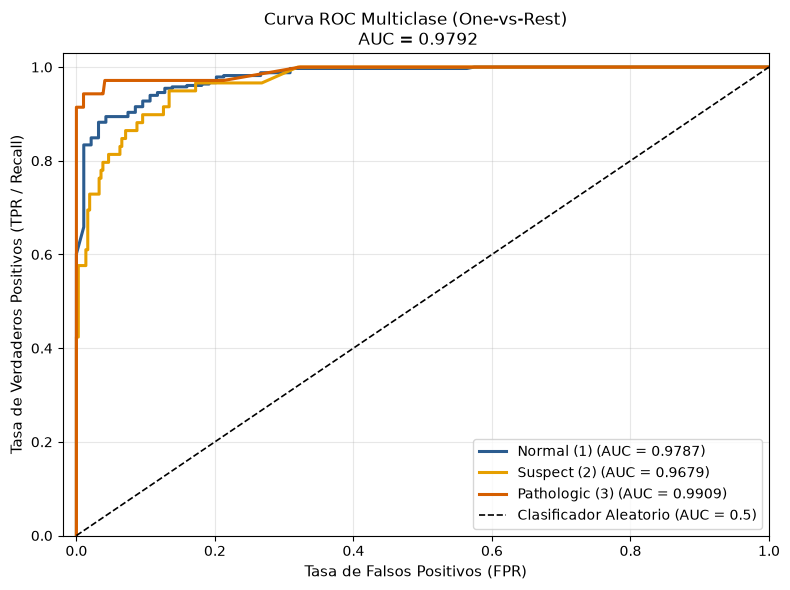

Macro AUC Global: 0.9792


In [7]:
macro_auc, aucs_por_clase = roc(forest_sklearn, X_test, y_test)
print(f"Macro AUC Global: {macro_auc:.4f}")

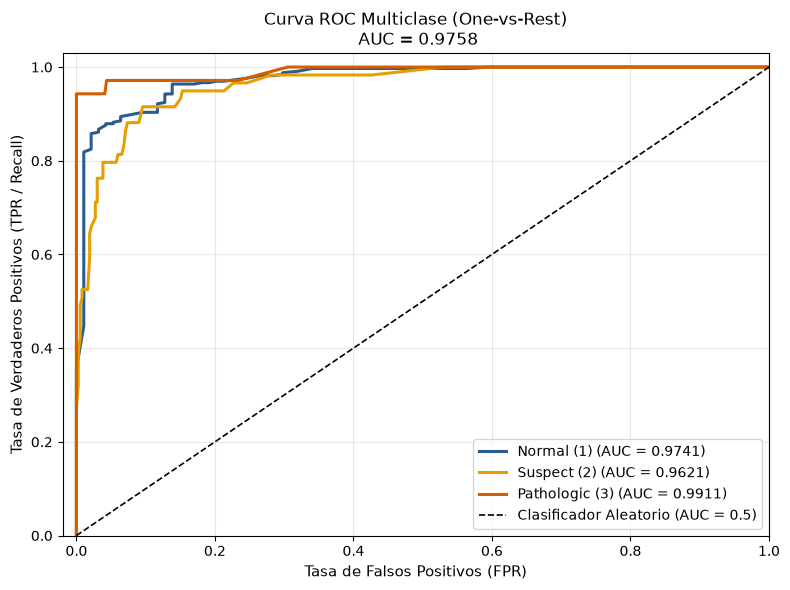

Macro AUC Global: 0.9758


In [8]:
# Nuestro Modelo
macro_auc, aucs_por_clase = roc(forest, X_test, y_test)
print(f"Macro AUC Global: {macro_auc:.4f}")

#### Conclusión de la Comparativa (Modelo Propio vs. Scikit-Learn)

Al comparar nuestro Random Forest hecho desde cero contra la versión de scikit-learn, observamos que **nuestro modelo ofrece una calidad igual o incluso mejor para este diagnóstico médico**:

* **Detección de riesgos:** Nuestro modelo detectó más bebés en estado crítico (**84.62%** de Recall en casos Patológicos frente al **76.92%** de scikit-learn) y logró un mejor equilibrio entre clases (**87.92%** vs. **85.98%** de Macro F1-Score), manteniendo una similar capacidad discriminativa (**0.9758** vs. **0.9820** de AUC).

* **Relación tiempo-calidad:** scikit-learn entrena mucho más rápido (**0.47 s** frente a **30.82 s**) porque está optimizado, mientras que nuestro código corre en Python puro. Sin embargo, al evaluar pacientes nuevos (predicción), ambos responden en pocos segundos (**0.20 s** vs. **0.13 s**), demostrando que nuestra implementación es viable y confiable.